# KDD — Chronic Kidney Disease Pattern Discovery

This notebook follows Selection, Preprocessing, Transformation, Data Mining, and Interpretation/Evaluation. Upload `kidney_disease.csv` to Colab or place it in `data/raw/`. This is an educational prototype, not a diagnostic system.

In [1]:
!wget -q -O /content/kidney_disease.csv https://raw.githubusercontent.com/ArjunAnil2000/Chronic-Kidney-Disease-dataset/master/kidney_disease.csv

In [2]:
import pandas as pd

kidney = pd.read_csv("/content/kidney_disease.csv")

print(kidney.shape)
display(kidney.head())

(400, 26)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,class
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


In [3]:
from pathlib import Path
import warnings; warnings.filterwarnings('ignore')
import joblib, numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.decomposition import TruncatedSVD
from sklearn.metrics import classification_report,roc_auc_score,average_precision_score,ConfusionMatrixDisplay, silhouette_score
sns.set_theme(style='whitegrid'); RANDOM_STATE=42
candidates=list(Path('data/raw').glob('*.csv')) if Path('data/raw').exists() else []
candidates += [Path('/content/kidney_disease.csv'),Path('/content/chronic_kidney_disease.csv')]
DATA_PATH=next((p for p in candidates if p.exists()),None)
if DATA_PATH is None: raise FileNotFoundError('Upload kidney_disease.csv or chronic_kidney_disease.csv, or place it in data/raw/')
raw=pd.read_csv(DATA_PATH,na_values=['?']); print('Loaded',DATA_PATH,raw.shape); display(raw.head())

Loaded /content/kidney_disease.csv (400, 26)


,id,age,bp,sg,al,su,rbc,pc,pcc,ba,...,pcv,wc,rc,htn,dm,cad,appet,pe,ane,class
0,0,48.0,80.0,1.020,1.0,0.0,NaN,normal,notpresent,notpresent,...,44,7800,5.2,yes,yes,no,good,no,no,ckd
1,1,7.0,50.0,1.020,4.0,0.0,NaN,normal,notpresent,notpresent,...,38,6000,NaN,no,no,no,good,no,no,ckd
2,2,62.0,80.0,1.010,2.0,3.0,normal,normal,notpresent,notpresent,...,31,7500,NaN,no,yes,no,poor,no,yes,ckd
3,3,48.0,70.0,1.005,4.0,0.0,normal,abnormal,present,notpresent,...,32,6700,3.9,yes,no,no,poor,yes,yes,ckd
4,4,51.0,80.0,1.010,2.0,0.0,normal,normal,notpresent,notpresent,...,35,7300,4.6,no,no,no,good,no,no,ckd


## 1. Selection

We select the kidney-disease classification target and remove non-predictive record identifiers. The original dataset contains mixed medical measurements and categorical fields.

In [4]:
df=raw.copy(); df.columns=[str(c).strip().lower().replace(' ','_') for c in df.columns]
target=next((c for c in ['classification','class','target','ckd'] if c in df.columns),df.columns[-1])
if 'id' in df.columns: df=df.drop(columns=['id'])
vals=df[target].astype(str).str.lower().str.replace('\s+','',regex=True)
df[target]=vals.map({'ckd':1,'ckd\t':1,'notckd':0,'notckd\t':0,'yes':1,'no':0}).fillna(pd.to_numeric(vals,errors='coerce'))
df=df.dropna(subset=[target]); y=df[target].astype(int); X=df.drop(columns=[target]);
print('Selected target:',target,'shape:',X.shape); display(y.value_counts().rename('count').to_frame())

Selected target: class shape: (400, 24)


,count
class,
1,250
0,150


## 2. Preprocessing

We normalize text values, coerce numeric-looking columns, inspect missingness, and split the data before fitting imputers or encoders.

In [5]:
for c in X.columns:
    if X[c].dtype=='object': X[c]=X[c].astype(str).str.strip().str.lower().replace({'nan':np.nan,'?':np.nan})
    converted=pd.to_numeric(X[c],errors='coerce')
    if converted.notna().mean()>.8: X[c]=converted
profile=pd.DataFrame({'dtype':X.dtypes.astype(str),'missing':X.isna().sum(),'missing_pct':(X.isna().mean()*100).round(2)}).sort_values('missing_pct',ascending=False); display(profile)
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=.2,stratify=y,random_state=RANDOM_STATE)
num=X_train.select_dtypes(include='number').columns.tolist(); cat=[c for c in X_train.columns if c not in num]
pre=ColumnTransformer([('num',Pipeline([('impute',SimpleImputer(strategy='median')),('scale',StandardScaler())]),num),('cat',Pipeline([('impute',SimpleImputer(strategy='most_frequent')),('onehot',OneHotEncoder(handle_unknown='ignore',sparse_output=False))]),cat)])
ARTIFACTS=Path('artifacts'); ARTIFACTS.mkdir(exist_ok=True)

,dtype,missing,missing_pct
rbc,object,152,38.00
rc,object,131,32.75
wc,object,106,26.50
pot,float64,88,22.00
sod,float64,87,21.75
pcv,float64,71,17.75
pc,object,65,16.25
hemo,float64,52,13.00
su,float64,49,12.25
sg,float64,47,11.75


## 3. Transformation

The pipeline transforms mixed-type inputs into a numeric matrix. We also project the transformed observations to two dimensions for visual interpretation.

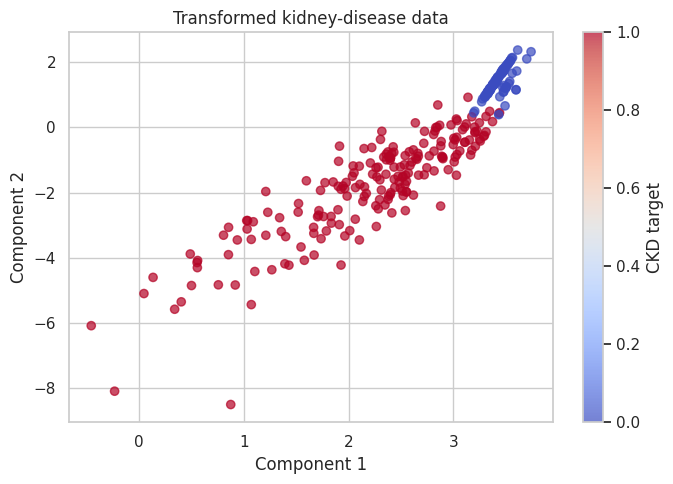

In [6]:
Z_train=pre.fit_transform(X_train); Z_test=pre.transform(X_test)
svd=TruncatedSVD(n_components=2,random_state=RANDOM_STATE); coords=svd.fit_transform(Z_train)
plt.figure(figsize=(7,5)); plt.scatter(coords[:,0],coords[:,1],c=y_train,cmap='coolwarm',alpha=.7); plt.xlabel('Component 1'); plt.ylabel('Component 2'); plt.title('Transformed kidney-disease data'); plt.colorbar(label='CKD target'); plt.tight_layout(); plt.savefig(ARTIFACTS/'transformed_projection.png',dpi=180); plt.show()

## 4. Data Mining

We perform supervised classification and unsupervised clustering. The classifiers predict the CKD label; K-means searches for two broad patterns without using the target.

,model,roc_auc,pr_auc,precision,recall,f1
1,random_forest,1.000000,1.000000,1.0,1.00,1.000000
0,logistic_regression,0.999333,0.999608,1.0,0.96,0.979592


,precision,recall,f1-score,support
0,1.0,1.0,1.0,30.0
1,1.0,1.0,1.0,50.0
accuracy,1.0,1.0,1.0,1.0
macro avg,1.0,1.0,1.0,80.0
weighted avg,1.0,1.0,1.0,80.0


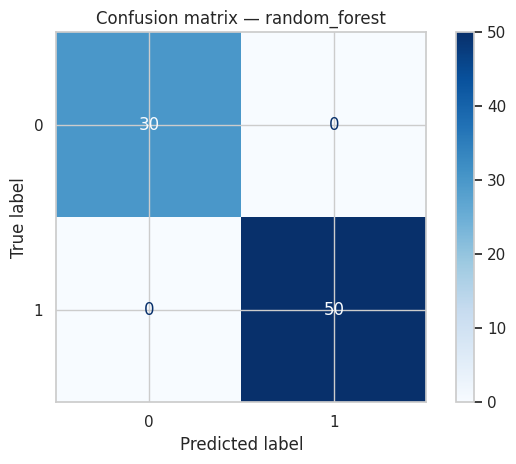

K-means silhouette score: 0.2014
class         0         1
row_0                    
0      0.718563  0.281437
1      0.000000  1.000000


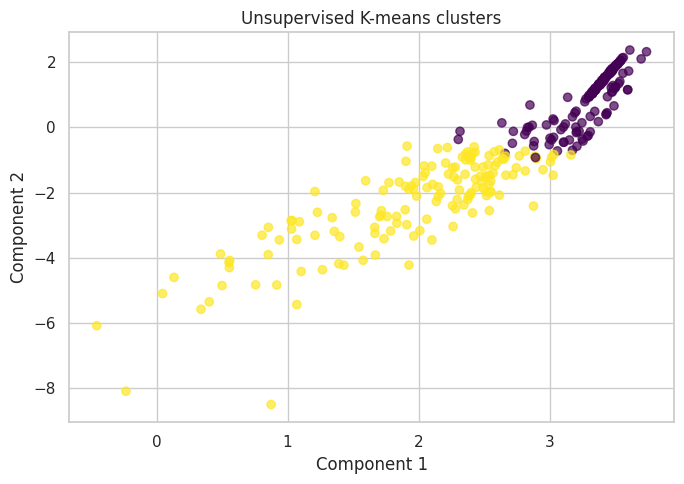

In [7]:
models={'logistic_regression':LogisticRegression(max_iter=1500,class_weight='balanced',random_state=RANDOM_STATE),'random_forest':RandomForestClassifier(n_estimators=300,class_weight='balanced',random_state=RANDOM_STATE,n_jobs=-1)}
rows=[]; fitted={}
for name,est in models.items():
    pipe=Pipeline([('preprocess',pre),('model',est)]); pipe.fit(X_train,y_train); p=pipe.predict_proba(X_test)[:,1]; pred=(p>=.5).astype(int); rep=classification_report(y_test,pred,output_dict=True,zero_division=0)
    rows.append({'model':name,'roc_auc':roc_auc_score(y_test,p),'pr_auc':average_precision_score(y_test,p),'precision':rep['1']['precision'],'recall':rep['1']['recall'],'f1':rep['1']['f1-score']}); fitted[name]=pipe
results=pd.DataFrame(rows).sort_values('roc_auc',ascending=False); results.to_csv(ARTIFACTS/'model_comparison.csv',index=False); display(results)
best_name=results.iloc[0]['model']; best=fitted[best_name]; pred=best.predict(X_test); display(pd.DataFrame(classification_report(y_test,pred,output_dict=True,zero_division=0)).T)
ConfusionMatrixDisplay.from_predictions(y_test,pred,cmap='Blues'); plt.title(f'Confusion matrix — {best_name}'); plt.tight_layout(); plt.savefig(ARTIFACTS/'confusion_matrix.png',dpi=180); plt.show(); joblib.dump(best,ARTIFACTS/'best_ckd_pipeline.joblib')
kmeans=KMeans(n_clusters=2,n_init=20,random_state=RANDOM_STATE); labels=kmeans.fit_predict(Z_train); print('K-means silhouette score:',round(silhouette_score(Z_train,labels),4)); print(pd.crosstab(labels,y_train,normalize='index'))
plt.figure(figsize=(7,5)); plt.scatter(coords[:,0],coords[:,1],c=labels,cmap='viridis',alpha=.7); plt.title('Unsupervised K-means clusters'); plt.xlabel('Component 1'); plt.ylabel('Component 2'); plt.tight_layout(); plt.savefig(ARTIFACTS/'kmeans_clusters.png',dpi=180); plt.show()

## 5. Interpretation and Evaluation

Interpret the results cautiously. A strong score on this small dataset does not establish clinical validity. Discuss missingness, sample size, population coverage, class balance, errors, and whether discovered clusters correspond to clinically meaningful subgroups. The final report must distinguish prediction from causation.

In [8]:
print('Saved artifacts to',ARTIFACTS)
print('Best classifier:',best_name)
print('Responsible-use note: external validation, clinical review, privacy review, and prospective impact assessment are required before real-world use.')

Saved artifacts to artifacts
Best classifier: random_forest
Responsible-use note: external validation, clinical review, privacy review, and prospective impact assessment are required before real-world use.
